# CNN translation experiment

In [1]:
from functools import partial

import torch

from cnn import (
    FlattenMLPImageClassifier,
    LearnableImageDataset,
    TwoConvClassifier,
    make_two_conv_classifier,
)
from cnn_evaluation import (
    embed_in_canvas,
    evaluate_rotation_generalization,
    evaluate_translation_generalization,
    print_transform_audit,
    rotate_images,
)
from meta_learning import MetaLearner
from meta_loss_functions import cross_entropy_loss, intra_class_diversity
from visualization import (
    plot_image_dataset,
    plot_meta_history,
    plot_rotation_example,
    plot_transform_accuracy,
)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Configuration

In [2]:
# Generated dataset
SEED = 42
NUM_CLASSES = 3
SAMPLES_PER_CLASS = 20
IMAGE_SIZE = 16
CANVAS_SIZE = 24
CHANNELS = 1

# CNN: Conv -> ReLU -> Conv -> ReLU -> Flatten -> Linear
FIRST_CONV_CHANNELS = 32
SECOND_CONV_CHANNELS = 64

# Inner learning
INNER_LR = 0.1
INNER_STEPS = 15
LEARNERS_PER_STEP = 2
TRAIN_FRACTION = 0.8

# Meta-optimization
META_STEPS = 500
META_LR = 0.05
DIVERSITY_WEIGHT = 2.0

# MLP baseline
MLP_HIDDEN_DIM = 128

# Transformation audits
SHIFT_LEVELS = [0, 1, 2, 3, 4]
ROTATION_LEVELS = [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0]
AUDIT_TRIALS = 100
TRANSFORMS_PER_TRIAL = 20
ROTATION_EXAMPLE_INDEX = 0
ROTATION_EXAMPLE_DEGREES = 45.0

torch.manual_seed(SEED)

## Meta-training for the CNN

In [3]:
generator = LearnableImageDataset(
    num_classes=NUM_CLASSES,
    samples_per_class=SAMPLES_PER_CLASS,
    image_size=IMAGE_SIZE,
    channels=CHANNELS,
)

cnn_factory = partial(
    make_two_conv_classifier,
    image_size=IMAGE_SIZE,
    channels=CHANNELS,
    first_channels=FIRST_CONV_CHANNELS,
    second_channels=SECOND_CONV_CHANNELS,
    pool_type="none",
)

meta_learner = MetaLearner(
    generator=generator,
    learner_factory=cnn_factory,
    inner_loss_fn=cross_entropy_loss,
    meta_loss_fn=cross_entropy_loss,
    regularization_fn=partial(
        intra_class_diversity,
        weight=DIVERSITY_WEIGHT,
    ),
    num_classes=NUM_CLASSES,
    meta_lr=META_LR,
    inner_lr=INNER_LR,
    inner_steps=INNER_STEPS,
    learners_per_step=LEARNERS_PER_STEP,
    train_fraction=TRAIN_FRACTION,
    first_order=False,
    seed=SEED,
)

step=0001 loss=0.7666 accuracy=0.208
step=0050 loss=0.0652 accuracy=0.667
step=0100 loss=-0.3282 accuracy=1.000
step=0150 loss=0.0347 accuracy=0.667
step=0200 loss=-0.4297 accuracy=1.000
step=0250 loss=-0.4527 accuracy=1.000
step=0300 loss=-0.4449 accuracy=1.000
step=0350 loss=-0.4401 accuracy=1.000
step=0400 loss=-0.4188 accuracy=1.000
step=0450 loss=-0.4589 accuracy=1.000
step=0500 loss=-0.4768 accuracy=1.000


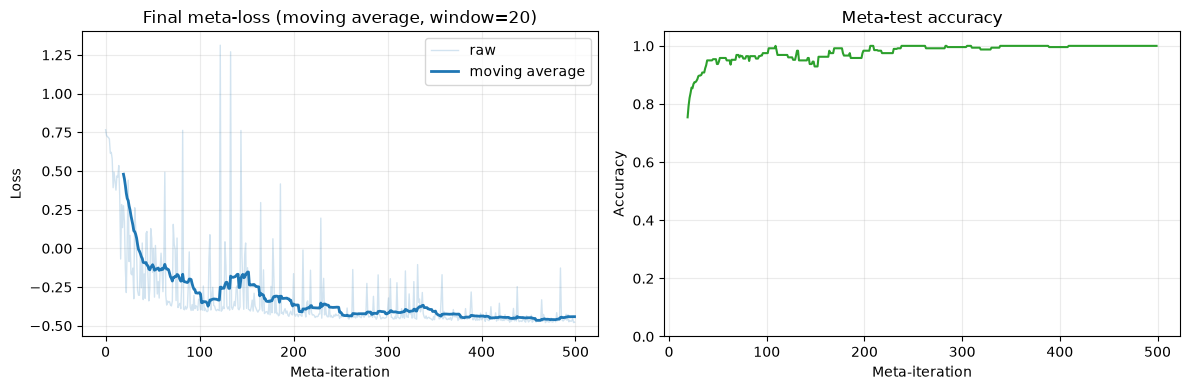

In [4]:
history = meta_learner.train(steps=META_STEPS, log_every=50)
x_frozen, y_frozen = meta_learner.frozen_dataset()
plot_meta_history(history, smoothing_window=20);

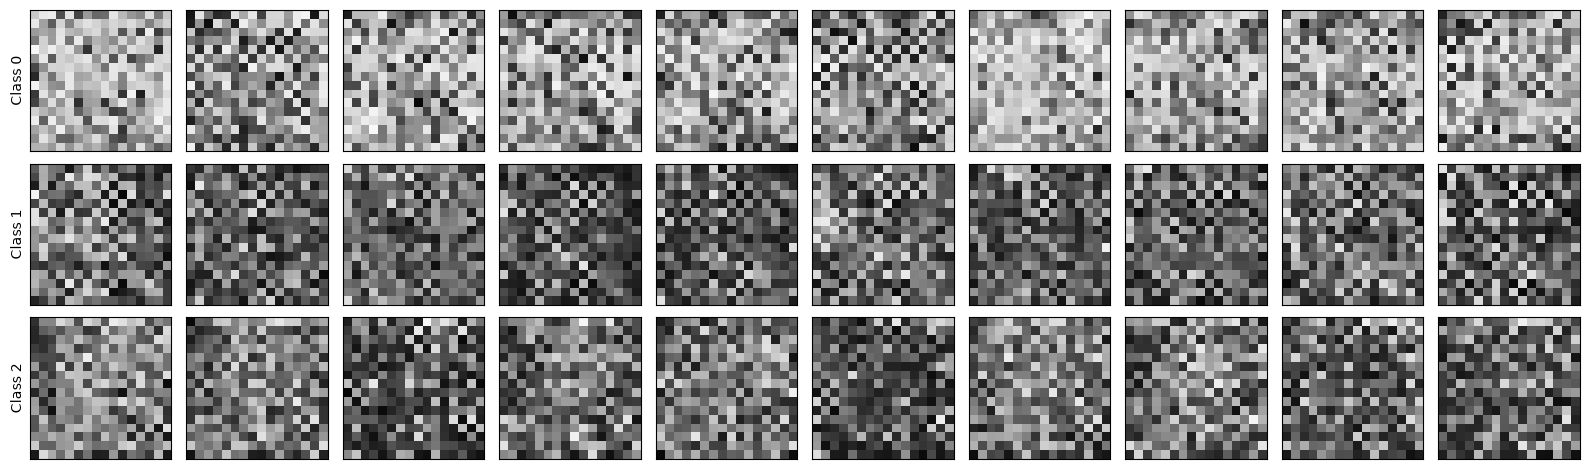

In [5]:
assert x_frozen.shape[-2:] == (IMAGE_SIZE, IMAGE_SIZE)
plot_image_dataset(x_frozen, y_frozen, samples_per_class=10);

## Translation audit

In [6]:
model_specs = {
    "CNN": (
        TwoConvClassifier,
        {
            "image_size": CANVAS_SIZE,
            "channels": CHANNELS,
            "first_channels": FIRST_CONV_CHANNELS,
            "second_channels": SECOND_CONV_CHANNELS,
            "pool_type": "none",
        },
    ),
    "MLP": (
        FlattenMLPImageClassifier,
        {
            "image_size": CANVAS_SIZE,
            "channels": CHANNELS,
            "hidden_dim": MLP_HIDDEN_DIM,
        },
    ),
}

x_canvas = embed_in_canvas(x_frozen, CANVAS_SIZE)

audit_common = dict(
    x=x_canvas,
    y=y_frozen,
    num_classes=NUM_CLASSES,
    trials=AUDIT_TRIALS,
    transforms_per_trial=TRANSFORMS_PER_TRIAL,
    train_fraction=TRAIN_FRACTION,
    training_steps=INNER_STEPS,
    learning_rate=INNER_LR,
)

CNN
  0: 0.9808 +- 0.0985
  1: 0.5472 +- 0.0551
  2: 0.5072 +- 0.0516
  3: 0.4728 +- 0.0508
  4: 0.4347 +- 0.0398
MLP
  0: 0.8333 +- 0.1586
  1: 0.4665 +- 0.0658
  2: 0.4165 +- 0.0522
  3: 0.4013 +- 0.0437
  4: 0.3986 +- 0.0452


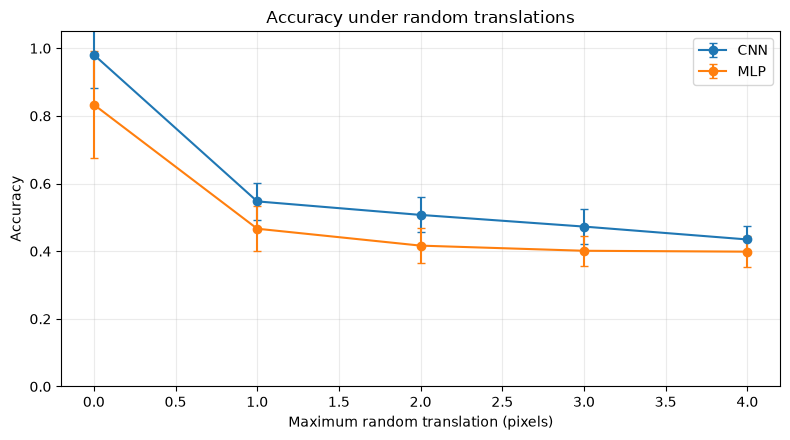

In [7]:
translation_summaries = {}
for name, (model_class, model_kwargs) in model_specs.items():
    translation_summaries[name] = evaluate_translation_generalization(
        model_class,
        model_kwargs,
        shift_levels=SHIFT_LEVELS,
        seed=10_000,
        **audit_common,
    )
    print_transform_audit(name, translation_summaries[name], "translation")

plot_transform_accuracy(
    list(translation_summaries.values()),
    list(translation_summaries.keys()),
    condition="translation",
);